<a href="https://colab.research.google.com/github/Annapurna29/gemini-ai-/blob/main/Copy_of_Untitled14.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Colab: make sure we have a clean environment
!pip -q install --upgrade pip
!pip -q install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121  # GPU build (Colab)
!pip -q install pennylane pennylane-lightning
!pip -q install albumentations==1.4.7 opencv-python tqdm timm==1.0.9 einops==0.8.0
!pip -q install matplotlib seaborn scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 23.0 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install torch torchvision
!pip install pennylane

In [ ]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from tqdm.notebook import tqdm
from torchvision import datasets, transforms, models
from torchvision.datasets import ImageFolder
from torchvision.transforms import ToTensor
from torchvision.utils import make_grid
from torch.utils.data import random_split
from torch.utils.data.dataloader import DataLoader
import matplotlib.pyplot as plt
%matplotlib inline

In [ ]:
data_dir = "/content/drive/MyDrive/medical_mnist"   # <<< CHANGE THIS
save_dir  = "/content/drive/MyDrive/models"                    # <<< CHANGE IF NEEDED
os.makedirs(save_dir, exist_ok=True)

In [ ]:
pip install torch torchvision pennylane matplotlib

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import pennylane as qml
import numpy as np

/usr/local/lib/python3.12/dist-packages/pennylane/__init__.py:209: RuntimeWarning: PennyLane is not yet compatible with JAX versions > 0.6.2. You have version 0.7.2 installed. Please downgrade JAX to 0.6.2 to avoid runtime errors using python -m pip install jax~=0.6.0 jaxlib~=0.6.0
  warnings.warn(


In [ ]:
train_transform = transforms.Compose([
        transforms.Grayscale(num_output_channels=1),  # force grayscale
        transforms.RandomRotation(10),
        transforms.RandomHorizontalFlip(),
        transforms.Resize(60),
        transforms.CenterCrop(60),
        transforms.ToTensor(),
        transforms.Normalize([0.5], [0.5])  # for 1 channel (mean=0.5, std=0.5)
])

dataset = ImageFolder(data_dir, transform=train_transform)
print('Size of training dataset :', len(dataset))

Size of training dataset : 14811


torch.Size([1, 60, 60])
Label:  AbdomenCT (0)


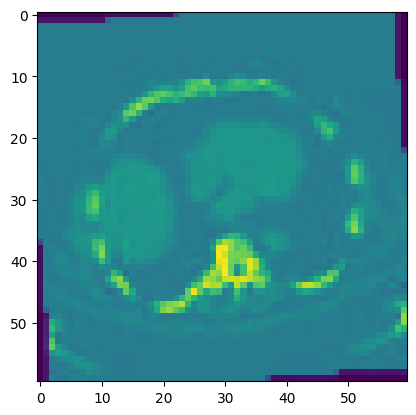

In [ ]:
img, label = dataset[100]
print(img.shape)
torch.Size([3, 60, 60])
# function for the showing the image.
def show_image(img, label):
    print('Label: ', dataset.classes[label], "("+str(label)+")")
    plt.imshow(img.permute(1,2,0))
show_image(*dataset[200])

In [ ]:
torch.manual_seed(20)
val_size = len(dataset)//10
test_size = len(dataset)//10
train_size = len(dataset) - val_size -test_size
train_ds, val_ds, test_ds = random_split(dataset, [train_size, val_size, test_size])
len(train_ds), len(val_ds),len(test_ds)

(11849, 1481, 1481)

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:627: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


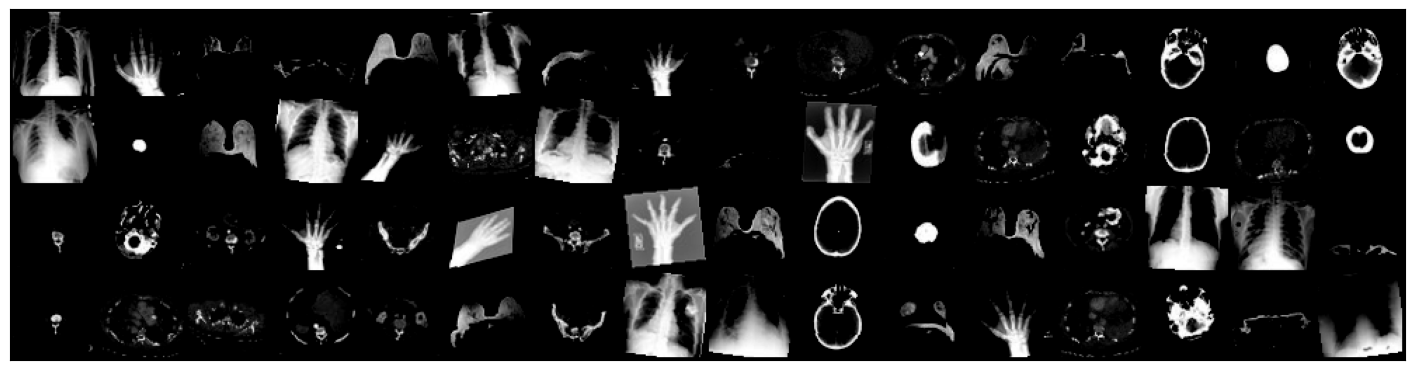

In [ ]:
batch_size = 64
train_loader = DataLoader(train_ds, batch_size, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size*2, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size*2, num_workers=4, pin_memory=True)
for images, labels in train_loader:
    fig, ax = plt.subplots(figsize=(18,10))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.imshow(make_grid(images, nrow=16).permute(1, 2, 0))
    break

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:156: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tensor(y, device=device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:177: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tenso

HQNN-Parallel | Epoch 01/10 | TrainLoss 0.8726 | TrainAcc 70.75% | TestLoss 0.4435 | TestAcc 84.81% | P 0.863 R 0.833 F1 0.821


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:156: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tensor(y, device=device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:177: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tenso

HQNN-Parallel | Epoch 02/10 | TrainLoss 0.4960 | TrainAcc 84.17% | TestLoss 0.3543 | TestAcc 87.68% | P 0.881 R 0.865 F1 0.860


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:156: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tensor(y, device=device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:177: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tenso

...

HQNN-Parallel | Epoch 08/10 | TrainLoss 0.3169 | TrainAcc 90.18% | TestLoss 0.2450 | TestAcc 91.46% | P 0.913 R 0.906 F1 0.904


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:156: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tensor(y, device=device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:177: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tenso

HQNN-Parallel | Epoch 09/10 | TrainLoss 0.3058 | TrainAcc 90.60% | TestLoss 0.2580 | TestAcc 90.92% | P 0.907 R 0.900 F1 0.898


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:156: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tensor(y, device=device)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:177: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tenso

HQNN-Parallel | Epoch 10/10 | TrainLoss 0.3089 | TrainAcc 90.49% | TestLoss 0.2337 | TestAcc 91.77% | P 0.914 R 0.910 F1 0.908
✅ Saved HQNN-Parallel to: /content/drive/MyDrive/models/hqnn_parallel_model.pth


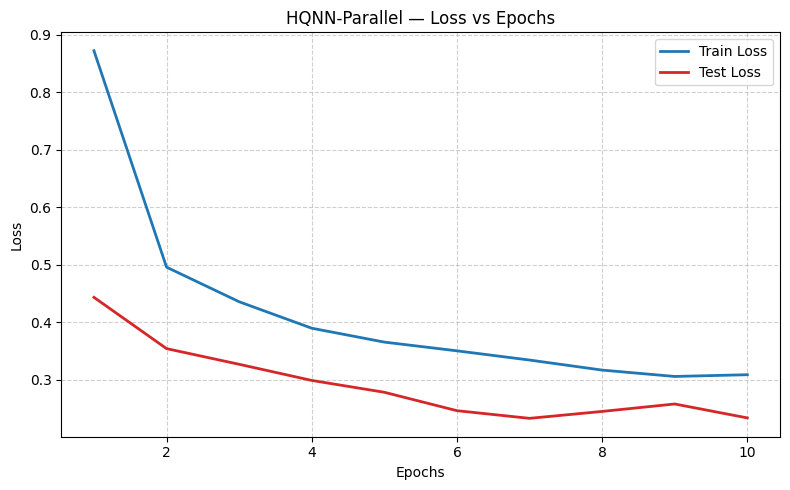

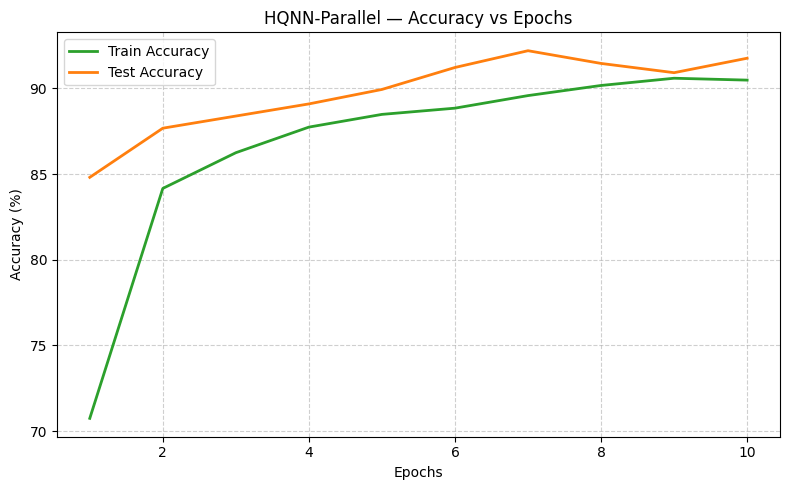

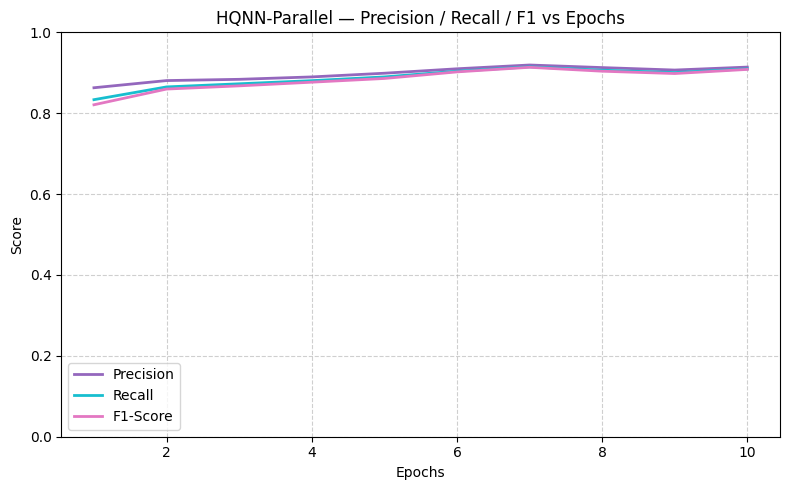

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:128: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tensor(y, device=device)


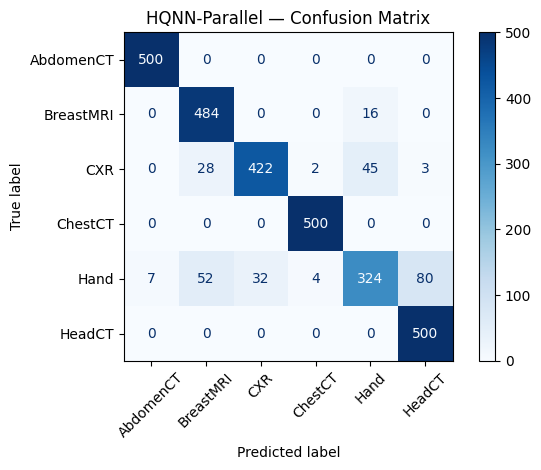

HQNN-Parallel — Test Acc: 91.77% | P:0.914 R:0.910 F1:0.908



/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/tmp/ipython-input-3732740613.py:271: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  x, y = x.to(device), torch.tensor(y, device=device)


📊 Classification Report — HQNN-Parallel
              precision    recall  f1-score   support

   AbdomenCT       0.99      1.00      0.99       556
   BreastMRI       0.86      0.97      0.91       465
         CXR       0.93      0.84      0.88       454
     ChestCT       0.99      1.00      0.99       506
        Hand       0.84      0.65      0.73       448
      HeadCT       0.88      1.00      0.93       534

    accuracy                           0.92      2963
   macro avg       0.91      0.91      0.91      2963
weighted avg       0.92      0.92      0.91      2963




In [ ]:
# =========================
# FULL DATASET TRAIN: HQNN-Parallel (80:20 split, epoch-wise test metrics + plots + classification report)
# =========================
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
    precision_score, recall_score, f1_score, classification_report
)
import pennylane as qml

# -------------------------
# CONFIG
# -------------------------
data_root = "/content/drive/MyDrive/medical_mnist"   # <<< CHANGE THIS
save_dir  = "/content/drive/MyDrive/models"
os.makedirs(save_dir, exist_ok=True)

img_size = 28
batch_hqnn = 32
epochs_hqnn = 10
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Try fast simulator; fallback if not available
try:
    q_device = qml.device("lightning.qubit", wires=4)
except Exception:
    q_device = qml.device("default.qubit", wires=4)

# -------------------------
# DATASET
# -------------------------
class FolderDataset(Dataset):
    def __init__(self, root, transform=None):
        self.samples = []
        self.categories = sorted([d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d))])
        self.transform = transform
        for label, cat in enumerate(self.categories):
            folder = os.path.join(root, cat)
            for fname in os.listdir(folder):
                fpath = os.path.join(folder, fname)
                if os.path.isfile(fpath):
                    self.samples.append((fpath, label))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        p, y = self.samples[idx]
        img = Image.open(p).convert("L")
        if self.transform: img = self.transform(img)
        return img, y

tfm = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor()
])

full_ds = FolderDataset(data_root, transform=tfm)
categories = full_ds.categories
n_classes = len(categories)

# -------------------------
# DATASET SPLIT (80-20)
# -------------------------
train_sz = int(0.8 * len(full_ds))
test_sz  = len(full_ds) - train_sz
train_ds, test_ds = random_split(full_ds, [train_sz, test_sz])

hqnn_train_loader = DataLoader(train_ds, batch_size=batch_hqnn, shuffle=True,  num_workers=2, pin_memory=True)
hqnn_test_loader  = DataLoader(test_ds,  batch_size=batch_hqnn, shuffle=False, num_workers=2, pin_memory=True)

# -------------------------
# HQNN-Parallel MODEL
# -------------------------
n_qubits = 4

@qml.qnode(q_device, interface="torch")
def qnode_single(x_vec, weights):
    # Encode 4 features
    for i in range(n_qubits):
        qml.RY(np.pi * x_vec[i], wires=i)
    # Variational layers
    for l in range(weights.shape[0]):
        for i in range(n_qubits):
            qml.RY(weights[l, i], wires=i)
        for i in range(n_qubits-1):
            qml.CNOT(wires=[i, i+1])
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

class HQNNParallel(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.q_weights = nn.Parameter(0.1 * torch.randn(6, n_qubits))
        self.post = nn.Sequential(
            nn.Linear(n_qubits, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        B = x.size(0)
        cols = torch.tensor([0, 9, 18, 27], device=x.device)
        feats = x[:, 0, 0, cols]  # take 4 pixels from first row

        qouts = []
        for i in range(B):
            qval = qnode_single(feats[i], self.q_weights)
            qouts.append(torch.stack(qval))
        qfeats = torch.stack(qouts, dim=0)
        return self.post(qfeats)

# -------------------------
# TRAIN / EVAL UTILITIES
# -------------------------
@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    all_y, all_p = [], []
    for x, y in loader:
        x, y = x.to(device), torch.tensor(y, device=device)
        logits = model(x)
        preds = logits.argmax(1)
        all_y.extend(y.cpu().numpy())
        all_p.extend(preds.cpu().numpy())
    acc = accuracy_score(all_y, all_p)
    prec = precision_score(all_y, all_p, average="macro", zero_division=0)
    rec = recall_score(all_y, all_p, average="macro", zero_division=0)
    f1 = f1_score(all_y, all_p, average="macro", zero_division=0)
    cm = confusion_matrix(all_y, all_p)
    return acc, prec, rec, f1, cm

# -------------------------
# TRAIN (with per-epoch test evaluation)
# -------------------------
def train(model, train_loader, test_loader, epochs, lr, name, save_path):
    model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()

    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": [], "test_prec": [], "test_rec": [], "test_f1": []}

    for ep in range(1, epochs+1):
        model.train()
        total_loss = 0.0
        all_y_train, all_p_train = [], []

        for x, y in train_loader:
            x, y = x.to(device), torch.tensor(y, device=device)
            opt.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            opt.step()
            total_loss += loss.item()

            preds = logits.argmax(1)
            all_y_train.extend(y.cpu().numpy())
            all_p_train.extend(preds.cpu().numpy())

        train_loss_epoch = total_loss / max(1, len(train_loader))
        train_acc = accuracy_score(all_y_train, all_p_train)

        # Evaluate on test set each epoch
        model.eval()
        total_test_loss = 0.0
        all_y_test, all_p_test = [], []
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), torch.tensor(y, device=device)
                logits = model(x)
                total_test_loss += criterion(logits, y).item()
                preds = logits.argmax(1)
                all_y_test.extend(y.cpu().numpy())
                all_p_test.extend(preds.cpu().numpy())

        test_loss_epoch = total_test_loss / max(1, len(test_loader))
        test_acc = accuracy_score(all_y_test, all_p_test)
        test_prec = precision_score(all_y_test, all_p_test, average="macro", zero_division=0)
        test_rec = recall_score(all_y_test, all_p_test, average="macro", zero_division=0)
        test_f1 = f1_score(all_y_test, all_p_test, average="macro", zero_division=0)

        hist["train_loss"].append(train_loss_epoch)
        hist["train_acc"].append(100.0 * train_acc)
        hist["test_loss"].append(test_loss_epoch)
        hist["test_acc"].append(100.0 * test_acc)
        hist["test_prec"].append(test_prec)
        hist["test_rec"].append(test_rec)
        hist["test_f1"].append(test_f1)

        print(f"{name} | Epoch {ep:02d}/{epochs} | TrainLoss {train_loss_epoch:.4f} | "
              f"TrainAcc {100.0*train_acc:.2f}% | TestLoss {test_loss_epoch:.4f} | "
              f"TestAcc {100.0*test_acc:.2f}% | P {test_prec:.3f} R {test_rec:.3f} F1 {test_f1:.3f}")

    torch.save(model.state_dict(), save_path)
    print(f"✅ Saved {name} to: {save_path}")
    return hist, model

# -------------------------
# PLOTTING HELPERS
# -------------------------
def plot_train_test(hist, title_prefix="Model"):
    epochs = range(1, len(hist["train_loss"]) + 1)

    # Combined Loss Plot
    plt.figure(figsize=(8,5))
    plt.plot(epochs, hist["train_loss"], label="Train Loss", color="tab:blue", linewidth=2)
    plt.plot(epochs, hist["test_loss"], label="Test Loss", color="tab:red", linewidth=2)
    plt.title(f"{title_prefix} — Loss vs Epochs")
    plt.xlabel("Epochs"); plt.ylabel("Loss")
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # Accuracy Plot
    plt.figure(figsize=(8,5))
    plt.plot(epochs, hist["train_acc"], label="Train Accuracy", color="tab:green", linewidth=2)
    plt.plot(epochs, hist["test_acc"], label="Test Accuracy", color="tab:orange", linewidth=2)
    plt.title(f"{title_prefix} — Accuracy vs Epochs")
    plt.xlabel("Epochs"); plt.ylabel("Accuracy (%)")
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

    # Precision / Recall / F1 Plot
    plt.figure(figsize=(8,5))
    plt.plot(epochs, hist["test_prec"], label="Precision", color="tab:purple", linewidth=2)
    plt.plot(epochs, hist["test_rec"], label="Recall", color="tab:cyan", linewidth=2)
    plt.plot(epochs, hist["test_f1"], label="F1-Score", color="tab:pink", linewidth=2)
    plt.title(f"{title_prefix} — Precision / Recall / F1 vs Epochs")
    plt.xlabel("Epochs"); plt.ylabel("Score")
    plt.ylim(0,1)
    plt.legend(); plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.show()

# -------------------------
# CONFUSION MATRIX + CLASSIFICATION REPORT
# -------------------------
@torch.no_grad()
def show_confusion_scaled(model, loader, categories, title):
    acc, prec, rec, f1, cm = evaluate(model, loader)

    # Normalize each row and scale to 500/class
    cm_scaled = []
    for i in range(len(cm)):
        row_sum = cm[i].sum()
        row_scaled = (cm[i] / row_sum) * 500.0 if row_sum > 0 else cm[i]
        cm_scaled.append(row_scaled)
    cm_scaled = np.array(cm_scaled).round().astype(int)

    disp = ConfusionMatrixDisplay(cm_scaled, display_labels=categories)
    disp.plot(cmap=plt.cm.Blues, xticks_rotation=45)
    plt.title(f"{title} — Confusion Matrix")
    plt.tight_layout()
    plt.show()

    print(f"{title} — Test Acc: {100*acc:.2f}% | P:{prec:.3f} R:{rec:.3f} F1:{f1:.3f}\n")

    # Classification Report
    all_y, all_p = [], []
    model.eval()
    for x, y in loader:
        x, y = x.to(device), torch.tensor(y, device=device)
        preds = model(x).argmax(1)
        all_y.extend(y.cpu().numpy())
        all_p.extend(preds.cpu().numpy())

    report = classification_report(all_y, all_p, target_names=categories, digits=2)
    print("="*75)
    print(f"📊 Classification Report — {title}")
    print("="*75)
    print(report)
    print("="*75 + "\n")

# -------------------------
# RUN HQNN-Parallel
# -------------------------
hqnn = HQNNParallel(n_classes)
hqnn_hist, hqnn = train(
    hqnn, hqnn_train_loader, hqnn_test_loader,
    epochs=epochs_hqnn, lr=5e-4,
    name="HQNN-Parallel",
    save_path=os.path.join(save_dir, "hqnn_parallel_model.pth")
)

plot_train_test(hqnn_hist, "HQNN-Parallel")
show_confusion_scaled(hqnn, hqnn_test_loader, categories, "HQNN-Parallel")


In [ ]:
import matplotlib.pyplot as plt

def plot_train_test(hist, title_prefix="Model"):
    epochs = range(1, len(hist["train_loss"]) + 1)

    # Create subplots: 1 row, 2 columns
    fig, axs = plt.subplots(1, 2, figsize=(10, 4))

    # --- Loss Plot ---
    axs[0].plot(epochs, hist["train_loss"], label="Train Loss", color="tab:blue", linewidth=2)
    axs[0].plot(epochs, hist["test_loss"], label="Test Loss", color="tab:red", linewidth=2)
    axs[0].set_title(f"{title_prefix} — Loss vs Epochs")
    axs[0].set_xlabel("Epochs")
    axs[0].set_ylabel("Loss")
    axs[0].legend()
    axs[0].grid(True, linestyle='--', alpha=0.6)

    # --- Accuracy Plot ---
    axs[1].plot(epochs, hist["train_acc"], label="Train Accuracy", color="tab:green", linewidth=2)
    axs[1].plot(epochs, hist["test_acc"], label="Test Accuracy", color="tab:orange", linewidth=2)
    axs[1].set_title(f"{title_prefix} — Accuracy vs Epochs")
    axs[1].set_xlabel("Epochs")
    axs[1].set_ylabel("Accuracy (%)")
    axs[1].legend()
    axs[1].grid(True, linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()


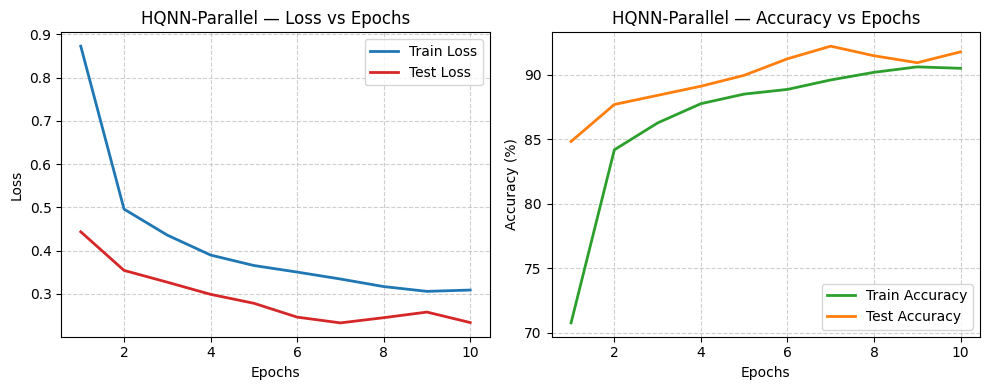

In [ ]:
plot_train_test(hqnn_hist, "HQNN-Parallel")

In [ ]:
# =========================
# HQNN-Qunavolutional - Reduced Overfitting Version
# =========================
from torchvision import transforms
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# --- Stronger augmentations ---
tfm = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.RandomRotation(15),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomAffine(degrees=10, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.5], [0.5])
])
data_root = "/content/drive/MyDrive/medical_mnist"
# Reload dataset with new augmentations
full_ds = FolderDataset(data_root, transform=tfm)
train_sz = int(0.8 * len(full_ds))
test_sz  = len(full_ds) - train_sz
train_ds, test_ds = random_split(full_ds, [train_sz, test_sz])

hqnn_train_loader = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2, pin_memory=True)
hqnn_test_loader  = DataLoader(test_ds,  batch_size=64, shuffle=False, num_workers=2, pin_memory=True)

# Get number of output classes
categories = full_ds.categories
n_classes = len(categories)
print("Number of classes:", n_classes)

n_qubits = 4  # Number of quantum wires (same as before)

# -------------------------
# Quantum Node Definition
# -------------------------
import pennylane as qml
import numpy as np

# Use a simulator (prefer lightning if available)
try:
    q_device = qml.device("lightning.qubit", wires=4)
except Exception:
    q_device = qml.device("default.qubit", wires=4)

@qml.qnode(q_device, interface="torch")
def qnode_single(x_vec, weights):
    """Single quantum variational circuit"""
    for i in range(n_qubits):
        qml.RY(np.pi * x_vec[i], wires=i)
    for l in range(weights.shape[0]):
        for i in range(n_qubits):
            qml.RY(weights[l, i], wires=i)
        for i in range(n_qubits - 1):
            qml.CNOT(wires=[i, i + 1])
    return [qml.expval(qml.PauliZ(i)) for i in range(n_qubits)]

# --- Modified Model (higher dropout) ---
class HQNNQunavolutional(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.q_weights = nn.Parameter(0.1 * torch.randn(6, n_qubits))
        self.pre_q = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 7 * 7, 64),
            nn.ReLU(),
            nn.Linear(64, n_qubits),
            nn.Sigmoid()
        )
        self.post = nn.Sequential(
            nn.Linear(n_qubits, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.5),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.4),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        B = x.size(0)
        z = self.conv(x)
        feats = self.pre_q(z)
        qouts = []
        for i in range(B):
            qval = qnode_single(feats[i], self.q_weights)
            qouts.append(torch.stack(qval))
        qfeats = torch.stack(qouts, dim=0)
        return self.post(qfeats)

# --- Early stopping + training ---
def train_with_early_stopping(model, train_loader, test_loader, epochs, lr, name, save_path, patience=3):
    model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.CrossEntropyLoss()

    best_loss = float('inf')
    patience_counter = 0
    hist = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for ep in range(1, epochs+1):
        model.train()
        total_loss, all_y_train, all_p_train = 0.0, [], []
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            opt.zero_grad()
            logits = model(x)
            loss = criterion(logits, y)
            loss.backward()
            opt.step()
            total_loss += loss.item()
            all_y_train.extend(y.cpu().numpy())
            all_p_train.extend(logits.argmax(1).cpu().numpy())

        train_loss = total_loss / len(train_loader)
        train_acc = accuracy_score(all_y_train, all_p_train)

        # Validation
        model.eval()
        total_val_loss, all_y_val, all_p_val = 0.0, [], []
        with torch.no_grad():
            for x, y in test_loader:
                x, y = x.to(device), y.to(device)
                logits = model(x)
                total_val_loss += criterion(logits, y).item()
                all_y_val.extend(y.cpu().numpy())
                all_p_val.extend(logits.argmax(1).cpu().numpy())

        val_loss = total_val_loss / len(test_loader)
        val_acc = accuracy_score(all_y_val, all_p_val)

        hist["train_loss"].append(train_loss)
        hist["train_acc"].append(100*train_acc)
        hist["test_loss"].append(val_loss)
        hist["test_acc"].append(100*val_acc)

        print(f"{name} | Epoch {ep:02d}/{epochs} | TrainLoss {train_loss:.4f} | TrainAcc {100*train_acc:.2f}% | "
              f"ValLoss {val_loss:.4f} | ValAcc {100*val_acc:.2f}%")

        # --- Early stopping check ---
        if val_loss < best_loss:
            best_loss = val_loss
            patience_counter = 0
            torch.save(model.state_dict(), save_path)
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print("⏹️ Early stopping triggered.")
                break

    print(f"✅ Best model saved to {save_path}")
    return hist, model

# --- Train HQNN model ---
hqnn_quna = HQNNQunavolutional(n_classes)
hqnn_quna_hist, hqnn_quna = train_with_early_stopping(
    hqnn_quna, hqnn_train_loader, hqnn_test_loader,
    epochs=5, lr=3e-4,
    name="HQNN-Qunavolutional (Regularized)",
    save_path=os.path.join(save_dir, "hqnn_qunavolutional_reg.pth")
)


Number of classes: 6


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


HQNN-Qunavolutional (Regularized) | Epoch 01/5 | TrainLoss 0.9153 | TrainAcc 68.84% | ValLoss 0.2226 | ValAcc 97.33%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


HQNN-Qunavolutional (Regularized) | Epoch 02/5 | TrainLoss 0.2103 | TrainAcc 95.54% | ValLoss 0.0909 | ValAcc 97.37%


...

HQNN-Qunavolutional (Regularized) | Epoch 03/5 | TrainLoss 0.1103 | TrainAcc 97.23% | ValLoss 0.0519 | ValAcc 98.28%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


HQNN-Qunavolutional (Regularized) | Epoch 04/5 | TrainLoss 0.0946 | TrainAcc 97.62% | ValLoss 0.0340 | ValAcc 98.89%


/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


HQNN-Qunavolutional (Regularized) | Epoch 05/5 | TrainLoss 0.0645 | TrainAcc 98.36% | ValLoss 0.0426 | ValAcc 98.38%
✅ Best model saved to /content/drive/MyDrive/models/hqnn_qunavolutional_reg.pth


In [ ]:
def plot_train_test(hist, name):
    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.plot(hist['train_loss'], label='Train Loss')
    plt.plot(hist['test_loss'], label='Test Loss')
    plt.title(f'{name} - Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(hist['train_acc'], label='Train Accuracy')
    plt.plot(hist['test_acc'], label='Test Accuracy')
    plt.title(f'{name} - Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.legend()
    plt.show()

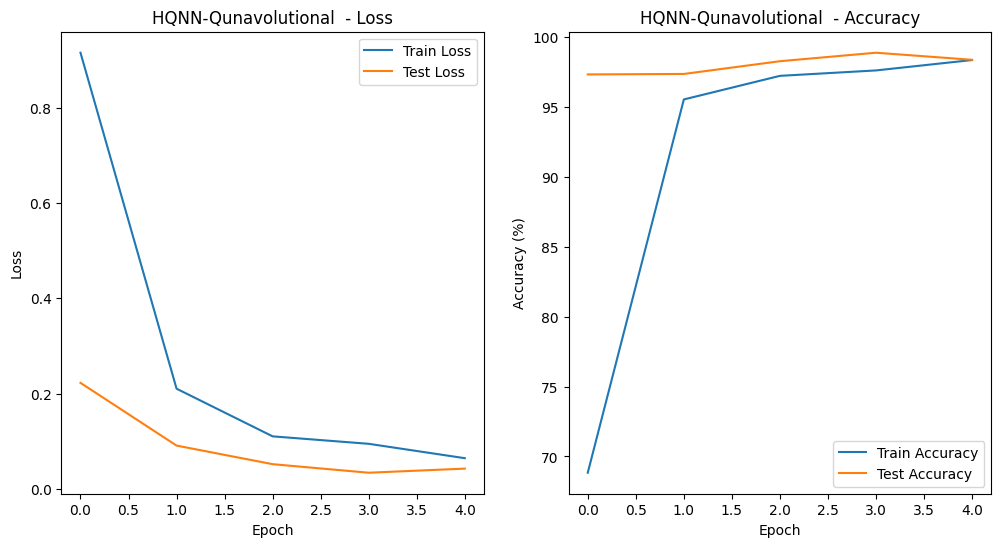

In [ ]:
plot_train_test(hqnn_quna_hist, "HQNN-Qunavolutional ")


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import numpy as np
import matplotlib.pyplot as plt

# --- Evaluation function ---
def evaluate_model(model, dataloader, class_names):
    model.eval()
    y_true = []
    y_pred = []

    with torch.no_grad():
        for images, labels in dataloader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            preds = torch.argmax(outputs, dim=1)
            y_true.extend(labels.cpu().numpy())
            y_pred.extend(preds.cpu().numpy())

    # --- Classification report ---
    print("=== Classification Report ===")
    print(classification_report(y_true, y_pred, target_names=class_names))

    # --- Confusion matrix ---
    cm = confusion_matrix(y_true, y_pred)
    plot_confusion_matrix(cm, class_names)

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

def plot_confusion_matrix(cm, class_names):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    fig, ax = plt.subplots(figsize=(7, 6))
    disp.plot(ax=ax, cmap='Blues', values_format='d', colorbar=True)
    plt.title("Confusion Matrix", fontsize=14)
    plt.xticks(rotation=45, ha='right', fontsize=10)
    plt.yticks(fontsize=10)
    plt.tight_layout()
    plt.show()

/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


=== Classification Report ===
              precision    recall  f1-score   support

 AbdomenCT         1.00      0.98      0.99       542
   BreastMRI       1.00      1.00      1.00       493
         CXR       0.95      1.00      0.97       469
     ChestCT       0.98      1.00      0.99       475
        Hand       1.00      0.95      0.97       477
      HeadCT       1.00      1.00      1.00       507

    accuracy                           0.99      2963
   macro avg       0.99      0.99      0.99      2963
weighted avg       0.99      0.99      0.99      2963



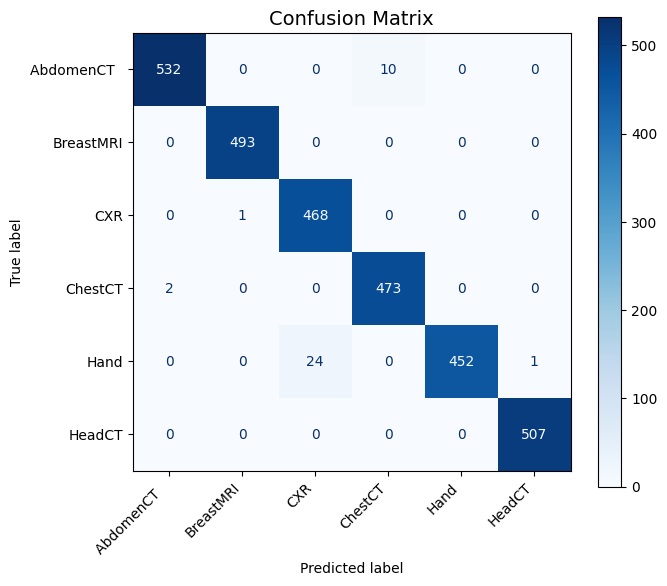

In [ ]:
evaluate_model(hqnn_quna, hqnn_test_loader,
               class_names=['AbdomenCT  ', 'BreastMRI', 'CXR', 'ChestCT', 'Hand', 'HeadCT'])
